<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/06_Ensemble_Learning/notebooks/05_Advanced_Model_Evaluation_and_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Model Evaluation and Validation

## Objectives
- Understand underfitting and overfitting.
- Understand bias and variance.
- Implement learning curves.
- Implement validation curves.
- Understand precision-recall tradeoff.
- Generate ROC curves and calculate AUC.
- Understand classification thresholds.

## Dataset
Wine Classification Dataset

## Algorithms
- Decision Tree
- Logistic Regression

## Evaluation Techniques
- Training and validation scores
- Learning curves
- Validation curves
- Precision and Recall
- ROC-AUC
- Classification threshold analysis

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    learning_curve,
    validation_curve
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

In [2]:
#Load the dataset
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = pd.Series(wine.target)

print("Features:", X.shape)
print("Target:", y.shape)
print("Classes:", wine.target_names)

Features: (178, 13)
Target: (178,)
Classes: ['class_0' 'class_1' 'class_2']


In [3]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 142
Testing records: 36


In [4]:
#Understand underfitting and overfitting practically
depths = [1, 3, None]

results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy
    })

depth_results = pd.DataFrame(results)

display(depth_results)

,Max Depth,Training Accuracy,Testing Accuracy
0,1,0.661972,0.583333
1,3,0.992958,0.944444
2,None,1.000000,0.944444


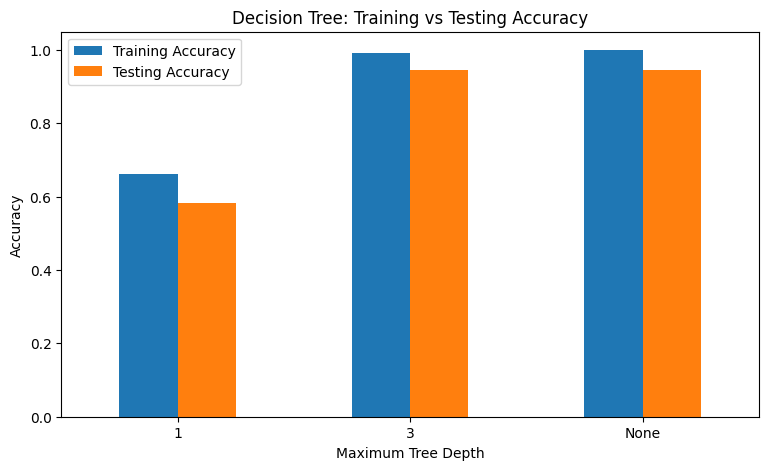

In [5]:
#Visualize the results
depth_results.set_index("Max Depth").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Decision Tree: Training vs Testing Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Maximum Tree Depth")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.show()

In [6]:
#Learning Curves
#We'll use a Decision Tree with maximum depth 3
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=tree_model,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Training sizes:", train_sizes)
print("Training scores shape:", train_scores.shape)
print("Validation scores shape:", validation_scores.shape)

Training sizes: [ 22  45  67  90 113]
Training scores shape: (5, 5)
Validation scores shape: (5, 5)


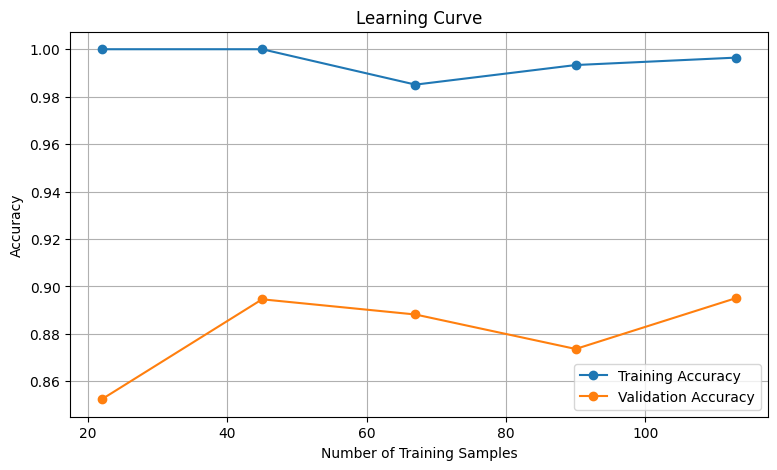

In [7]:
#Plot learning curve
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)

plt.show()

In [8]:
#Validation Curves
param_range = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]

train_scores, validation_scores = validation_curve(
    estimator=DecisionTreeClassifier(random_state=42),
    X=X_train,
    y=y_train,
    param_name="max_depth",
    param_range=param_range,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

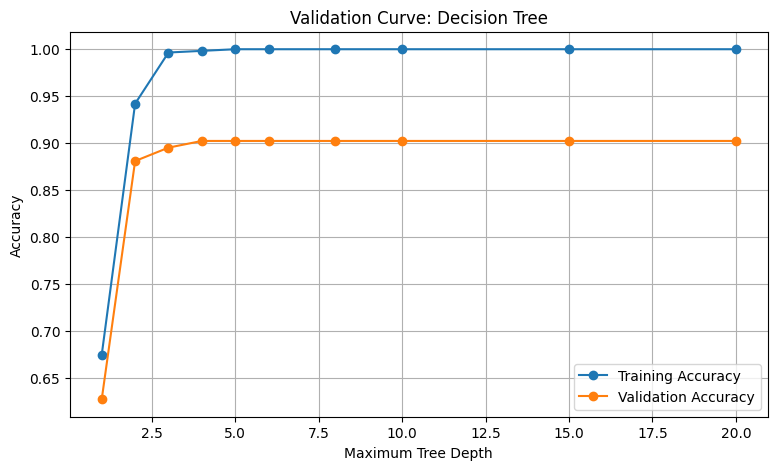

In [9]:
#Visualize validation curve
plt.figure(figsize=(9, 5))

plt.plot(
    param_range,
    train_mean,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    param_range,
    validation_mean,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Validation Curve: Decision Tree")
plt.legend()
plt.grid(True)

plt.show()

In [10]:
#Precision-Recall curve
#Create binary dataset
from sklearn.datasets import make_classification

X_binary, y_binary = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    weights=[0.8, 0.2],
    random_state=42
)

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_binary,
    y_binary,
    test_size=0.2,
    stratify=y_binary,
    random_state=42
)

print("Training shape:", Xb_train.shape)
print("Testing shape:", Xb_test.shape)

Training shape: (800, 10)
Testing shape: (200, 10)


In [11]:
#Train Logistic Regression
binary_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

binary_model.fit(Xb_train, yb_train)

probabilities = binary_model.predict_proba(Xb_test)[:, 1]

print(probabilities[:10])

[0.16890638 0.00862859 0.03665737 0.20446728 0.00378913 0.01109914
 0.00653705 0.01908551 0.01547894 0.17789336]


In [12]:
#Generate Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(
    yb_test,
    probabilities
)

average_precision = average_precision_score(
    yb_test,
    probabilities
)

print("Average Precision:", average_precision)

Average Precision: 0.6621526315852176


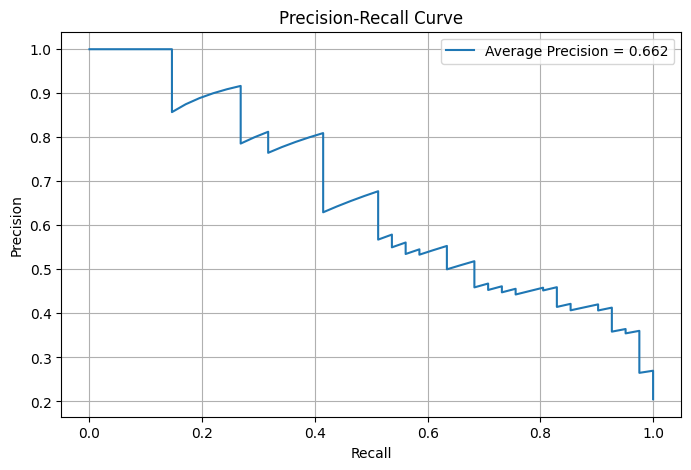

In [13]:
#Visualize
plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f"Average Precision = {average_precision:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)

plt.show()

In [14]:
#ROC Curve and AUC
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    yb_test,
    probabilities
)

roc_auc = roc_auc_score(
    yb_test,
    probabilities
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8631691977297131


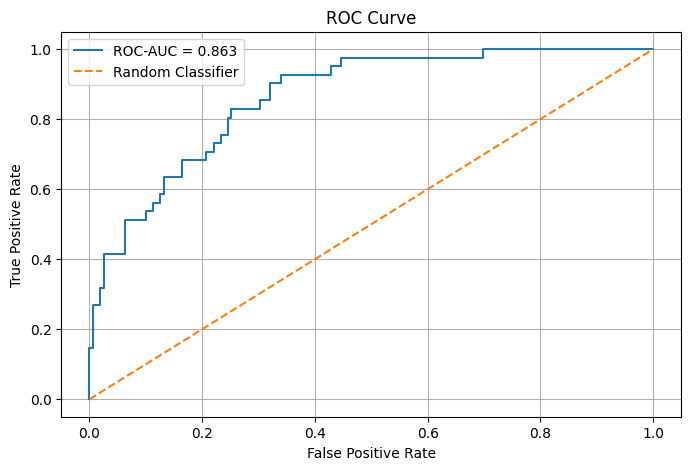

In [15]:
#Plot ROC curve
plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
#Classification Threshold Tuning
thresholds_to_test = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results = []

for threshold in thresholds_to_test:

    predictions = (
        probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            yb_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            yb_test,
            predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            yb_test,
            predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results)

,Threshold,Precision,Recall,F1 Score
0,0.2,0.459459,0.829268,0.591304
1,0.3,0.518519,0.682927,0.589474
2,0.4,0.560976,0.560976,0.560976
3,0.5,0.642857,0.439024,0.521739
4,0.6,0.777778,0.341463,0.474576
5,0.7,0.800000,0.292683,0.428571
6,0.8,0.857143,0.146341,0.250000


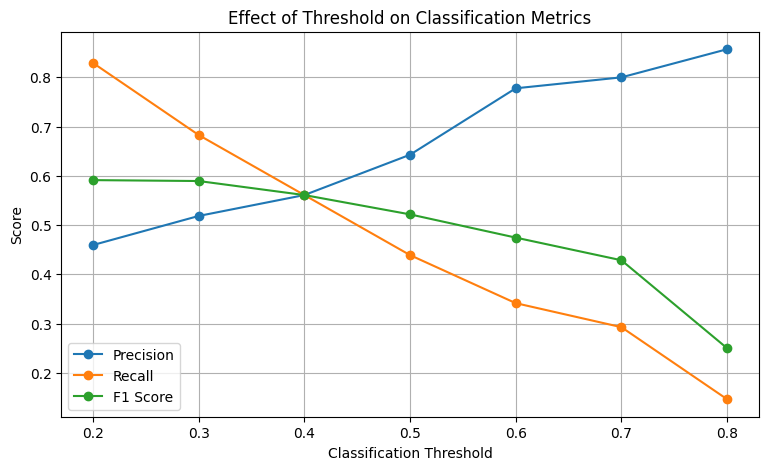

In [17]:
#Visualize threshold effects
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Effect of Threshold on Classification Metrics")
plt.legend()
plt.grid(True)

plt.show()